In [1]:
import numpy as np
import cobra
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pickle
import sys
sys.path.append('../../')
from helper_function import *

defualt_path = '../../'

plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12

cobra.Configuration.solver = 'glpk'

In [2]:
with open(defualt_path + 'FBAsolution/M9_sufficient_423_1_proteome_weakbg.pkl', 'rb') as pickle_file:
    data2 = pickle.load(pickle_file)
    all_total_nutrient_count2 = data2['all_total_nutrient_count']
    all_total_intake2 = data2['all_total_intake']
    all_growth_rate2 = data2['all_growth_rate']
    all_random_medium2 = data2['all_random_medium']
    all_met_flux2 = data2['all_met_flux']
    del data2

with open(defualt_path + 'FBAsolution/M9_sufficient_20_40_proteome_weakbg.pkl', 'rb') as pickle_file:
    data = pickle.load(pickle_file)
    all_total_nutrient_count = data['all_total_nutrient_count']
    all_total_intake = data['all_total_intake']
    all_growth_rate = data['all_growth_rate']
    all_random_medium = data['all_random_medium']
    all_met_flux = data['all_met_flux']
    del data

In [3]:
import pandas as pd
import ast
modelname = pd.read_excel('../../AGORA2_models/ModelList.xlsx')
modelname = np.array(modelname['ModelName'])

auxotrophic_content = pd.read_excel('../../auxotrophic&content.xlsx')
total_auxotrophic = [(ast.literal_eval(s)) for s in list(auxotrophic_content['New Auxotrophic'])]
total_auxotrophic_count = [len(s) for s in total_auxotrophic]

with open(defualt_path + 'Coarse_graining_result/clustered_nodes_c10_s44_pq1_relabeled.pkl', 'rb') as f:
    cluster_nodes = pickle.load(f)

In [4]:
def specialized_identification(G, start_node):
    path = [start_node]
    current = start_node

    while True:
        try:
            successors = list(G.successors(current))
        except:
            return False
        if len(successors) != 1:
            break 
        next_node = successors[0]

        if len(path) > 6:
            break
        
        if 'bio' in next_node:
            return True
        
        path.append(next_node)
        current = next_node

    return False

def classify_specialized_omnipotent(G, met_flux):
    nutrients = sorted([rec+'_bwd' for rec, value in met_flux if 'EX_' in rec and value < -0.01])
    specialized = []
    ominipotent = []
    for nutrient in nutrients:
        if specialized_identification(G, nutrient):
            specialized.append(nutrient[:-4])
        else:
            ominipotent.append(nutrient[:-4])   
    return specialized, ominipotent

In [5]:
import gc
from scipy.sparse import load_npz
simple_G = []
complex_G = []
selected = []
specialized = []
ominipotent = []
for j, (met_flux, met_flux2) in enumerate(zip(all_met_flux[0], all_met_flux2[0])):
    # if modelname[j][1:-5] not in ['Escherichia_coli_str_K_12_substr_MG1655']:
    #     continue
    try:
        with open(defualt_path + 'FBAsolution/flow_graph_20_1e-5/'+'0_'+modelname[j][1:-5]+'.pkl', 'rb') as f:
            G1 = pickle.load(f)
        with open(defualt_path + 'FBAsolution/flow_graph_423_1e-5/'+'0_'+modelname[j][1:-5]+'.pkl', 'rb') as f:
            G2 = pickle.load(f)
        
        specialized_1, ominipotent_1 = classify_specialized_omnipotent(G1, met_flux)
        specialized_2, ominipotent_2 = classify_specialized_omnipotent(G2, met_flux2)


        specialized.append((len((specialized_1)), len(set(specialized_2) | set(total_auxotrophic[j]))))
        ominipotent.append((len(ominipotent_1), len(ominipotent_2)))

        selected.append(j)

    except Exception as e:
        print(e)
        continue

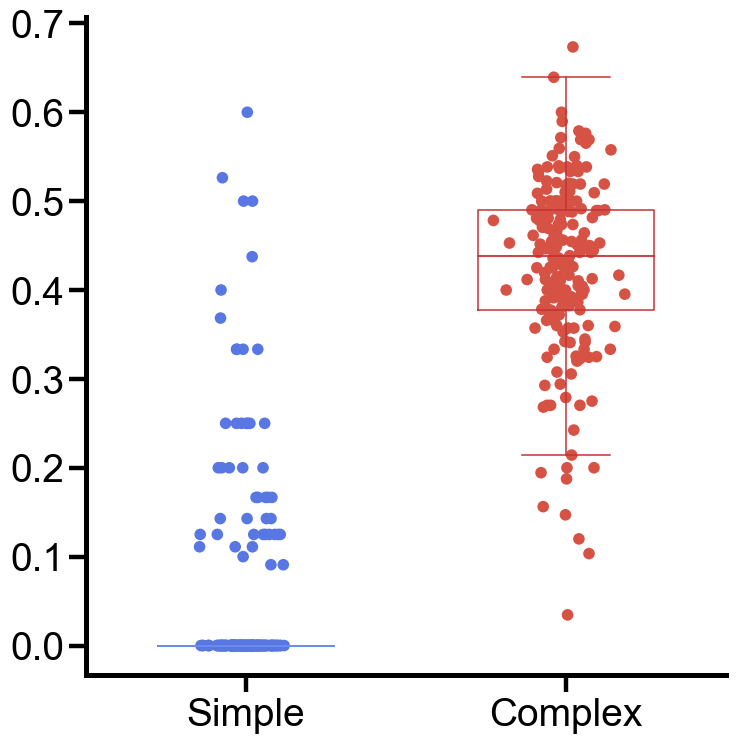

In [6]:
set_panel_style(scale=4)

spec = np.asarray(specialized, dtype=float)

omni = np.asarray(ominipotent, dtype=float)

den1 = spec[:, 0] + omni[:, 0]
den2 = spec[:, 1] + omni[:, 1]

x1 = np.divide(spec[:, 0], den1, out=np.full_like(den1, np.nan), where=(den1 != 0))
x2 = np.divide(spec[:, 1], den2, out=np.full_like(den2, np.nan), where=(den2 != 0))

mask = ~np.isnan(x1) & ~np.isnan(x2)
x1_clean = x1[mask]
x2_clean = x2[mask]

# ---- plotting ----
fig, ax = plt.subplots(figsize=(8, 8))

data = [x1_clean, x2_clean]
positions = [1, 2]


cmap = plt.get_cmap('coolwarm')
num_colors = 20
colors = [cmap(i / num_colors) for i in range(num_colors)]

complex_line_color = colors[19] #17 18
complex_scatter_color = colors[18] #3 2

simple_line_color = colors[3]
simple_scatter_color = colors[2]


bp = ax.boxplot(
    data,
    positions=positions,
    widths=0.55,
    showfliers=False,
    patch_artist=False,   # no fill
    boxprops=dict(linewidth=1.1),
    whiskerprops=dict(linewidth=1.1),
    capprops=dict(linewidth=1.1),
    medianprops=dict(linewidth=1.3),
)

# ---- set per-group colors (Simple then Complex) ----
group_line_colors = [simple_line_color, complex_line_color]

# boxes
for box, c in zip(bp["boxes"], group_line_colors):
    box.set_color(c)

# medians
for med, c in zip(bp["medians"], group_line_colors):
    med.set_color(c)

# whiskers: 2 per group
for gi, c in enumerate(group_line_colors):
    bp["whiskers"][2*gi].set_color(c)
    bp["whiskers"][2*gi + 1].set_color(c)

# caps: 2 per group
for gi, c in enumerate(group_line_colors):
    bp["caps"][2*gi].set_color(c)
    bp["caps"][2*gi + 1].set_color(c)

# ---- jittered scatter (different colors) ----
rng = np.random.default_rng(0)
j1 = positions[0] + rng.normal(0, 0.06, size=len(x1_clean))
j2 = positions[1] + rng.normal(0, 0.06, size=len(x2_clean))

ax.scatter(j1, x1_clean, s=70, color=simple_scatter_color, edgecolors="none")
ax.scatter(j2, x2_clean, s=70, color=complex_scatter_color,  edgecolors="none")

ax.set_xticks(positions)
ax.set_xticklabels(["Simple", "Complex"])

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
#fig.savefig("Supp_Figure3.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)
plt.show()